# Module 14: SQL Case Studies and Python Integration Foundations
**ALY 6420 | Applied analytics, PostgreSQL connectivity, pandas and safe parameters**

*Course Lecture Notes*

## Module 14
Module 13 extended SQL into recursion and statistics; Phase 4 connects these capabilities to repeatable Python workflows.

## Learning objectives
- Translate business questions into validated multi-step SQL.
- Decide when SQL alone is sufficient and when Python adds value.
- Connect to PostgreSQL using psycopg2; execute and fetch results.
- Load query results into pandas and create labeled visualizations.
- Bind dynamic values safely rather than interpolate SQL strings.

Resources : 
- Shan et al. (2025), *SQL for Data Analytics*, 4th ed.: Chapter 4, pp. 65–80 

## Environment and safe execution
Use DBeaver for fenced SQL blocks; Python cells are executable in Jupyter. Install in the notebook kernel environment, then restart if necessary:

```python
%pip install psycopg2-binary pandas matplotlib sqlalchemy jupyter
```
Use a Python version supported by your installed packages (3.11+ is a sensible starting point). Use a read-only database account where available. Offline mode is the default; live cells run only after you opt in below.

In [19]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
LIVE = False  # change to True only when ready to connect to Neon

Imports establish the Python analysis layer. No database connection is opened yet.

Reference dataset (offline): Synthetic sales Data: One row represents one transaction. February is missing, one customer has no known state, and one customer makes no purchases. These cases expose denominator and date-gap errors.

In [20]:
customers = pd.DataFrame({'customer_id':[1,2,3,4,5], 'state':['CA','TX','CA',None,'WA']})
products = pd.DataFrame({'product_id':[1,2,3], 'model':['Swift','Volt','Metro']})
sales = pd.DataFrame({'customer_id':[1,2,1,3,4,2], 'product_id':[1,2,2,1,3,3], 'sales_amount':[100,300,250,150,200,100], 'sales_transaction_date':pd.to_datetime(['2021-01-02','2021-01-15','2021-03-01','2021-03-05','2021-04-01','2021-04-08'])})
display(sales)

,customer_id,product_id,sales_amount,sales_transaction_date
0,1,1,100,2021-01-02
1,2,2,300,2021-01-15
2,1,2,250,2021-03-01
3,3,1,150,2021-03-05
4,4,3,200,2021-04-01
5,2,3,100,2021-04-08


Expected: six transactions, $1,100 revenue; known - state revenue $900. The fixture permits offline chart and DataFrame practice, not PostgreSQL execution.

# Part 1 - The SQL case study framework
## 1.1 Question → tables → technique → query and interpretation
A question specifies a measurable outcome, population and comparison. Then identify tables and join keys, choose the simplest appropriate technique, execute and validate, and interpret results for a decision.

| Stage | Example |
|---|---|
| Question | Which product models contribute the most revenue? |
| Tables | sales fact rows, products dimension |
| Technique | JOIN + GROUP BY + SUM |
| Query and interpretation | Rank revenue, check coverage, investigate concentration |

Chapter 14 connects transactional systems (OLTP) to analytical delivery through staging, quality checks and dimensional data. Here we read existing tables rather than build a warehouse.

```sql
SELECT current_database(), current_schema(), version();
SELECT table_schema, table_name, column_name, data_type
FROM information_schema.columns
WHERE table_name IN ('sales','customers','products','emails','dealerships')
ORDER BY table_schema, table_name, ordinal_position;
```

Check `sales_transaction_date`, `model`, `sales_amount` and join keys before running applied SQL. Establish whether sales rows represent units, transactions or line items.

```sql
SELECT product_id, COUNT(*) FROM products GROUP BY product_id HAVING COUNT(*) > 1;
SELECT customer_id, COUNT(*) FROM customers GROUP BY customer_id HAVING COUNT(*) > 1;
SELECT COUNT(*) AS sales_rows, COUNT(sales_amount) AS priced_rows,
       SUM(sales_amount) AS revenue FROM sales;
SELECT COUNT(*) AS unmatched_products FROM sales s
LEFT JOIN products p ON s.product_id = p.product_id WHERE p.product_id IS NULL;
```

Duplicate dimension keys can multiply sales rows; unmatched keys can silently remove them in inner joins. Reconcile totals before interpreting a report.

### Example 14.1: Reconcile a service inventory join

**Goal and context.** Left join keeps unmatched facts for investigation.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import pandas as pd
facts = pd.DataFrame({'asset':[1,2,3],'cost':[10,20,30]})
dim = pd.DataFrame({'asset':[1,2],'site':['East','West']})
result = facts.merge(dim,on='asset',how='left',validate='many_to_one',indicator=True)
assert result.cost.sum()==60
print(result['_merge'].value_counts())
```

**Expected result:** 2 both, 1 left_only, 0 right_only.

**Derived practice:** Change to inner join. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

Cost falls to 30.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

## 1.2 Product price and consistency 
Question: Which models generate revenue and how dispersed are their observed sale amounts?

```sql
SELECT p.model, COUNT(*) AS sales_rows,
       COUNT(s.sales_amount) AS priced_rows,
       ROUND(AVG(s.sales_amount)::numeric,2) AS avg_sale_price,
       ROUND(STDDEV(s.sales_amount)::numeric,2) AS price_stddev,
       ROUND(SUM(s.sales_amount)::numeric,2) AS total_revenue
FROM sales s JOIN products p ON s.product_id=p.product_id
GROUP BY p.model ORDER BY total_revenue DESC NULLS LAST, p.model;
```

A high standard deviation indicates variation, not proof of negotiation or discounting. A single priced observation yields NULL sample standard deviation. Group by product ID as well if the model name is not unique and product-level reporting is needed.

In [21]:
joined = sales.merge(products,on='product_id',validate='many_to_one').merge(customers,on='customer_id',validate='many_to_one')
product_summary = joined.groupby('model',as_index=False).agg(sales_rows=('sales_amount','size'),avg_sale_price=('sales_amount','mean'),price_stddev=('sales_amount','std'),total_revenue=('sales_amount','sum')).sort_values('total_revenue',ascending=False)
display(product_summary)
assert product_summary.total_revenue.sum() == 1100

,model,sales_rows,avg_sale_price,price_stddev,total_revenue
2,Volt,2,275.0,35.355339,550
0,Metro,2,150.0,70.710678,300
1,Swift,2,125.0,35.355339,250


Expected synthetic revenue: Volt $550, Metro $300, Swift $250. Volt drives half of total revenue. Investigate whether volume or price accounts for that concentration; the fixture is not evidence about the actual company.

### Example 14.2: Measure repair turnaround

**Goal and context.** Equal means can hide different uncertainty.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import pandas as pd
repair = pd.DataFrame({'team':['A','A','B'],'hours':[2,6,4]})
print(repair.groupby('team').hours.agg(['count','mean','std']))
```

**Expected result:** A: n=2 mean=4 SD≈2.828; B: n=1 mean=4 SD NaN.

**Derived practice:** Add a B repair lasting 8 hours. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

B mean 6, SD≈2.828.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

## 1.3 Geographic concentration
Calculate shares before limiting to top markets. Define the denominator as revenue from customers with known states and avoid rounding intermediate totals.

```sql
WITH state_revenue AS (
 SELECT c.state, SUM(s.sales_amount)::numeric AS total_revenue, COUNT(*) AS transactions
 FROM sales s JOIN customers c ON s.customer_id=c.customer_id
 WHERE c.state IS NOT NULL GROUP BY c.state
)
SELECT state, ROUND(total_revenue,2) AS total_revenue, transactions,
 ROUND(100*total_revenue/NULLIF(SUM(total_revenue) OVER (),0),2) AS pct_of_total
FROM state_revenue ORDER BY total_revenue DESC NULLS LAST,state LIMIT 10;
```

In [22]:
state_summary = joined.dropna(subset=['state']).groupby('state',as_index=False).sales_amount.sum().rename(columns={'sales_amount':'total_revenue'})
state_summary['pct_of_total'] = 100*state_summary.total_revenue/state_summary.total_revenue.sum()
display(state_summary.sort_values('total_revenue',ascending=False))

,state,total_revenue,pct_of_total
0,CA,500,55.555556
1,TX,400,44.444444


Expected CA $500 (55.56%), TX $400 (44.44%). The excluded $200 is not zero revenue; disclose its exclusion. Concentration may motivate risk analysis, not an automatic decision to exit a market.

## 1.4 Customer repeat activity
Question: What fraction of buying customers have multiple recorded sales? Use a customer-grain CTE before aggregating.

```sql
WITH buyer_activity AS (
 SELECT customer_id, COUNT(*) AS sales_rows FROM sales
 WHERE customer_id IS NOT NULL GROUP BY customer_id
)
SELECT COUNT(*) AS buyers, COUNT(*) FILTER (WHERE sales_rows>1) AS repeat_buyers,
 ROUND(100.0*COUNT(*) FILTER (WHERE sales_rows>1)/NULLIF(COUNT(*),0),2) AS repeat_pct
FROM buyer_activity;
```

Expected fixture: 4 buyers, 2 repeat buyers, 50%. This is repeat recorded sales, not necessarily retention over a defined time horizon.

## 1.5 Monthly trend 
The export refers to a DATE_TRUNC/LAG query but omits its expanded tab. This independent example uses a gap-free calendar so LAG means previous calendar month, not previous observed month.

```sql
WITH monthly AS (
 SELECT DATE_TRUNC('month',sales_transaction_date)::date AS month_start,
        SUM(sales_amount)::numeric AS revenue
 FROM sales WHERE sales_transaction_date >= DATE '2021-01-01'
 AND sales_transaction_date < DATE '2022-01-01' GROUP BY 1
), calendar AS (
 SELECT gs::date AS month_start FROM generate_series(DATE '2021-01-01',DATE '2021-12-01',INTERVAL '1 month') gs
), filled AS (
 SELECT c.month_start, CASE WHEN m.month_start IS NULL THEN 0 ELSE m.revenue END AS revenue
 FROM calendar c LEFT JOIN monthly m USING (month_start)
), lagged AS (
 SELECT *, LAG(revenue) OVER (ORDER BY month_start) AS prev_revenue FROM filled
)
SELECT month_start,revenue,prev_revenue,
 ROUND(100*(revenue-prev_revenue)/NULLIF(prev_revenue,0),2) AS mom_pct
FROM lagged ORDER BY month_start;
```

A missing month denotes zero recorded revenue only if data coverage is complete; an all-NULL observed month stays unknown. Growth from zero is undefined. The first month has no comparison inside the selected range.

In [23]:
monthly = sales.groupby(sales.sales_transaction_date.dt.to_period('M')).sales_amount.sum().reindex(pd.period_range('2021-01','2021-04',freq='M'),fill_value=0)
prev = monthly.shift()
display(pd.DataFrame({'revenue':monthly,'previous':prev,'mom_pct':100*(monthly-prev)/prev.where(prev.ne(0))}))

,revenue,previous,mom_pct
2021-01,400,NaN,NaN
2021-02,0,400.0,-100.0
2021-03,400,0.0,NaN
2021-04,300,400.0,-25.0


Expected Jan $400, Feb $0, Mar $400, Apr $300; April change -25%. March percent growth is undefined.

### Example 14.3: Track warehouse stock movements

**Goal and context.** A missing day is zero movement only if the feed is complete.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import pandas as pd
movement = pd.Series([10,-3,5],index=pd.to_datetime(['2025-01-01','2025-01-03','2025-01-04']))
print(movement.asfreq('D',fill_value=0).cumsum())
```

**Expected result:** 10,10,7,12.

**Derived practice:** Add a movement of -2 on Jan 2. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

10,8,5,10.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

## 1.6 SQL or Python?
| Need | Prefer |
|---|---|
| One filtered or grouped result | SQL / DBeaver |
| Large joins or aggregations near the data | SQL |
| Repeated parameterized reports | Python orchestration + SQL |
| Labeled charts, cross-system analysis, statistical modeling | Python after SQL retrieval |

Evidence-based management: define department turnover denominator before computing a relationship to manager tenure. Applied AI: count latency violations by model version over a defined time range. These are transferable examples, not claims that those tables exist in sqlda.

# Part 2 - Connecting Python to PostgreSQL
## 2.1 Connection, cursor, execute, fetch
The server executes SQL; Python receives results. A connection manages a database session; a cursor submits statements and fetches rows. Transactions begin automatically by default. A psycopg2 connection context commits or rolls back on exit but **does not close the connection**. Use `contextlib.closing` for guaranteed closure. Cursor contexts close cursors.

In [24]:
from contextlib import closing
from getpass import getpass
if LIVE:
    import psycopg2
    from sqlalchemy import create_engine, text
    from sqlalchemy.engine import URL
    from psycopg2.extensions import parse_dsn
    dsn = os.environ.get('NEON_DATABASE_URL') or getpass('Paste Neon connection URI (hidden): ')
    def connect():
        return psycopg2.connect(dsn, sslmode='require', connect_timeout=10)
    with closing(connect()) as conn:
        conn.set_session(readonly=True)
        with conn, conn.cursor() as cur:
            cur.execute('SELECT current_database(), current_schema()')
            print('Connection successful:', cur.fetchone())

Use Neon’s connection details. `sslmode=require` requires encryption.

In [25]:
if LIVE:
    with closing(connect()) as conn:
        conn.set_session(readonly=True)
        with conn, conn.cursor() as cur:
            cur.execute('SELECT model FROM products ORDER BY model LIMIT 5')
            rows = cur.fetchall()
            print(rows)

`fetchall()` returns a list of remaining tuples (empty list if none); `fetchone()` returns one tuple or None at exhaustion. `fetchmany(n)` retrieves a batch. A regular cursor may buffer the result; for genuinely large results investigate named cursors or streaming rather than assuming batching alone limits all memory.

In [26]:
if LIVE:
    with closing(connect()) as conn:
        conn.set_session(readonly=True)
        with conn, conn.cursor() as cur:
            cur.execute('SELECT COUNT(*) FROM customers')
            print('Customer rows:',cur.fetchone()[0])

A single scalar is a natural cursor use case. No DataFrame is needed. Close idle sessions and avoid long-lived transactions.

## 2.2 Troubleshooting
| Symptom | Check |
|---|---|
| ModuleNotFoundError | Install in the active kernel, restart |
| Timeout / DNS | Host, network, Neon availability, connection timeout |
| Authentication failure | Correct role, password, database details |
| Relation does not exist | Database, schema/search_path, privileges |
| Transaction aborted | Roll back before reuse; context exits can do this |


### Example 14.4: Distinguish no rows from connection failure

**Goal and context.** SQLite is an offline demonstration of DB-API behavior, not a PostgreSQL connection test.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import sqlite3
from contextlib import closing
with closing(sqlite3.connect(':memory:')) as conn:
    conn.execute('CREATE TABLE alerts(level TEXT)')
    print(conn.execute('SELECT * FROM alerts').fetchall())
    try:
        conn.execute('SELECT * FROM missing_table')
    except sqlite3.OperationalError as exc:
        print(type(exc).__name__)
```

**Expected result:** [] then OperationalError.

**Derived practice:** Insert one alert before SELECT. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

One tuple is returned.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

# Part 3 - pandas and SQLAlchemy
Modern pandas documents SQLAlchemy connectables for PostgreSQL; raw psycopg2 DBAPI connections are not officially supported by pandas read_sql (even if some versions accept them). The course allows the raw pattern; the main path here uses SQLAlchemy 2.x. An engine is a reusable connection factory/pool, not a continuously open cursor.

In [27]:
if LIVE:
    cfg = parse_dsn(dsn)
    url = URL.create('postgresql+psycopg2', username=cfg['user'], password=cfg['password'], host=cfg['host'], port=int(cfg.get('port',5432)), database=cfg['dbname'], query={k:v for k,v in cfg.items() if k not in {'user','password','host','port','dbname'}})
    engine = create_engine(url, connect_args={'sslmode':'require','connect_timeout':10,'options':'-c default_transaction_read_only=on'}, pool_pre_ping=True)

URL.create avoids manual password quoting. This example targets standard Neon URIs; if your deployment uses special connection options, follow its connection guidance. Engine creation is lazy; actual connectivity is checked on first use. Read-only options are additional safeguards, not a replacement for restricted privileges.

In [28]:
revenue_query = """SELECT p.model, SUM(s.sales_amount)::numeric AS total_revenue
FROM sales s JOIN products p ON s.product_id=p.product_id
GROUP BY p.model ORDER BY total_revenue DESC NULLS LAST,p.model"""
if LIVE:
    with engine.connect() as db:
        df = pd.read_sql(text(revenue_query), db)
else:
    df = product_summary[['model','total_revenue']].copy()
display(df.head())

,model,total_revenue
2,Volt,550
0,Metro,300
1,Swift,250


PostgreSQL performs the join and aggregation in live mode; only the resulting grouped rows travel into Python. Offline mode substitutes the fixture summary. `head()` previews already retrieved rows; it is not a server-side LIMIT.

In [29]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
display(df.describe(include='all'))

(3, 2)
model              str
total_revenue    int64
dtype: object
model            0
total_revenue    0
dtype: int64


,model,total_revenue
count,3,3.000000
unique,3,NaN
top,Volt,NaN
freq,1,NaN
mean,NaN,366.666667
std,NaN,160.727513
min,NaN,250.000000
25%,NaN,275.000000
50%,NaN,300.000000
75%,NaN,425.000000


Validate grain, null counts and numeric types before charting. pandas may convert Decimal values to float by default; for exact financial reconciliation keep exact SQL numeric totals or use coerce_float=False and handle Decimal deliberately.

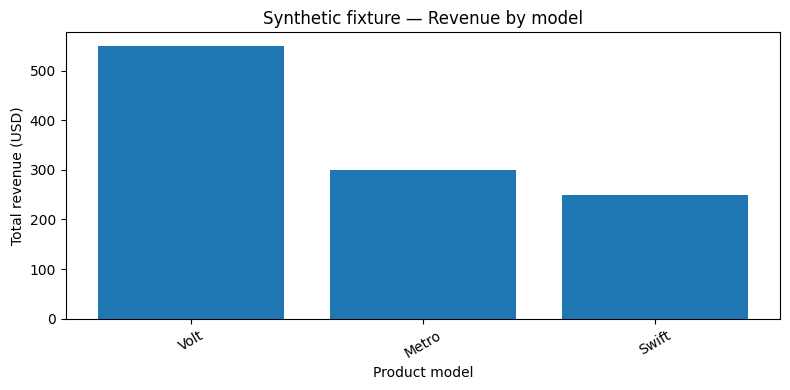

In [30]:
plot_df = df.dropna(subset=['total_revenue']).copy()
plot_df['total_revenue'] = pd.to_numeric(plot_df['total_revenue'])
fig, ax = plt.subplots(figsize=(8,4))
ax.bar(plot_df['model'],plot_df['total_revenue'])
ax.set(xlabel='Product model',ylabel='Total revenue (USD)',title=('ZoomZoom' if LIVE else 'Synthetic fixture')+' — Revenue by model')
ax.tick_params(axis='x',labelrotation=30)
fig.tight_layout()
plt.show()

A bar chart compares categorical totals. For the fixture, Volt leads. For live data, write your own observation, explain a possible business implication and identify a limitation. Confirm the currency before labeling actual results USD.

### Example 14.5: Push aggregation into the database

**Goal and context.** SQL reduces three rows to two before transfer; use PostgreSQL driver syntax in live mode.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import sqlite3, pandas as pd
from contextlib import closing
with closing(sqlite3.connect(':memory:')) as conn:
    conn.execute('CREATE TABLE readings(site TEXT, kwh INTEGER)')
    conn.executemany('INSERT INTO readings VALUES (?,?)',[('A',10),('A',15),('B',5)])
    print(pd.read_sql_query('SELECT site,SUM(kwh) AS kwh FROM readings GROUP BY site ORDER BY site',conn))
```

**Expected result:** A 25, B 5.

**Derived practice:** Add B 7. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

B total 12.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

# Part 4 - Parameterized queries
## 4.1 Values are not SQL syntax
Never use f-strings, concatenation or Python `%` formatting to insert external values into a SQL statement. Binding lets the driver adapt types safely. The following is an illustrative anti-pattern, not executable lecture code:

```python
# UNSAFE — do not execute with variable input
query = f"SELECT customer_id FROM customers WHERE state = '{state}'"
```
A value containing an apostrophe must remain data, not alter SQL structure. Parameters protect value positions; identifiers and SQL keywords require separate handling (allowlists or psycopg2.sql.Identifier).

In [31]:
state = 'CA'
if LIVE:
    with closing(connect()) as conn:
        conn.set_session(readonly=True)
        with conn, conn.cursor() as cur:
            cur.execute('SELECT COUNT(*) FROM customers WHERE state = %s', (state,))
            print(cur.fetchone()[0])
else:
    print(customers.state.eq(state).sum())

2


Expected offline CA customer count: 2. `%s` is used for all psycopg2 value types, without surrounding SQL quotes; `(state,)` is a one-element tuple.

In [32]:
if LIVE:
    from datetime import date
    with closing(connect()) as conn:
        conn.set_session(readonly=True)
        with conn, conn.cursor() as cur:
            cur.execute('SELECT COUNT(*) FROM sales WHERE sales_transaction_date >= %s AND sales_transaction_date < %s', (date(2021,1,1),date(2022,1,1)))
            print(cur.fetchone()[0])

Typed dates and a half-open range preserve timestamp boundary semantics and ordinary index eligibility. Modify the period after checking your dataset.

## 4.2 SQLAlchemy named binds with pandas
Use `text()` and `:name` placeholders with a dictionary. The driver-level alternative is a raw SQL string with `%s` and tuple parameters through a psycopg2-backed SQLAlchemy connection. Do not mix the two syntaxes.

In [33]:
filtered_query = """SELECT p.model, SUM(s.sales_amount)::numeric AS total_revenue
FROM sales s JOIN products p ON s.product_id=p.product_id
JOIN customers c ON s.customer_id=c.customer_id
WHERE c.state = :state GROUP BY p.model
ORDER BY total_revenue DESC NULLS LAST,p.model"""
if LIVE:
    with engine.connect() as db:
        df_filtered = pd.read_sql(text(filtered_query),db,params={'state':state})
else:
    df_filtered = joined.loc[joined.state.eq(state)].groupby('model',as_index=False).sales_amount.sum().rename(columns={'sales_amount':'total_revenue'}).sort_values(['total_revenue','model'],ascending=[False,True])
display(df_filtered)

,model,total_revenue
0,Swift,250
1,Volt,250


Expected CA: Swift $250, Volt $250. A tie is real; use deterministic secondary sorting. A parameterized report is reusable with another state without editing SQL.

In [34]:
if LIVE:
    with engine.connect() as db:
        driver_example = pd.read_sql('SELECT COUNT(*) AS customer_count FROM customers WHERE state = %s', db, params=(state,))
        display(driver_example)

This driver-style example matches Canvas parameter syntax. Prefer the named-bind approach for portable SQLAlchemy code.

In [35]:
ranked_query = """WITH model_revenue AS (
SELECT p.model, SUM(s.sales_amount)::numeric AS total_revenue
FROM sales s JOIN products p ON s.product_id=p.product_id
JOIN customers c ON s.customer_id=c.customer_id WHERE c.state=:state GROUP BY p.model)
SELECT model,total_revenue,DENSE_RANK() OVER (ORDER BY total_revenue DESC NULLS LAST) AS revenue_rank
FROM model_revenue ORDER BY revenue_rank,model"""
if LIVE:
    with engine.connect() as db:
        df_ranked = pd.read_sql(text(ranked_query),db,params={'state':state})
else:
    df_ranked = df_filtered.copy()
    df_ranked['revenue_rank'] = df_ranked.total_revenue.rank(method='dense',ascending=False).astype(int)
display(df_ranked)

,model,total_revenue,revenue_rank
0,Swift,250,1
1,Volt,250,1


Both fixture models rank 1. Ranking follows aggregation and filtering. In live data, an empty filter result is a valid outcome; distinguish it from a connection failure.

### Example 14.6: Parameter binding with untrusted text

**Goal and context.** The value is data, not executable SQL. SQLite uses ?, psycopg2 uses %s.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import sqlite3
from contextlib import closing
with closing(sqlite3.connect(':memory:')) as conn:
    conn.execute('CREATE TABLE assets(name TEXT)')
    conn.execute('INSERT INTO assets VALUES (?)',('pump',))
    value = "pump' OR 1=1 --"
    print(conn.execute('SELECT name FROM assets WHERE name=?',(value,)).fetchall())
```

**Expected result:** [].

**Derived practice:** Change value to pump. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

[('pump',)].

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

# Part 5 - Applied workflow and plan annotation
## 5.1 Measure the monthly trend query
Run in DBeaver after confirming date range. EXPLAIN ANALYZE executes the SELECT. Never invent plan timings.

```sql
EXPLAIN (ANALYZE, BUFFERS)
WITH monthly AS (
 SELECT DATE_TRUNC('month',sales_transaction_date)::date AS month_start,
        SUM(sales_amount)::numeric AS revenue
 FROM sales WHERE sales_transaction_date >= DATE '2021-01-01'
 AND sales_transaction_date < DATE '2022-01-01' GROUP BY 1
), calendar AS (
 SELECT gs::date AS month_start FROM generate_series(DATE '2021-01-01',DATE '2021-12-01',INTERVAL '1 month') gs
), filled AS (
 SELECT c.month_start, CASE WHEN m.month_start IS NULL THEN 0 ELSE m.revenue END AS revenue
 FROM calendar c LEFT JOIN monthly m USING (month_start)
), lagged AS (
 SELECT *, LAG(revenue) OVER (ORDER BY month_start) AS prev_revenue FROM filled
)
SELECT month_start,revenue,prev_revenue,
 ROUND(100*(revenue-prev_revenue)/NULLIF(prev_revenue,0),2) AS mom_pct
FROM lagged ORDER BY month_start;
```

What do you observe? node with highest actual time, sales scan type and reason, estimated versus actual rows, and one efficiency observation. Parent times include child work and per-loop times need loop context. A high cumulative root time does not identify the exclusive bottleneck. A sequential scan can be reasonable for a broad reporting period; inspect selectivity and buffers before proposing an index.

Compare counts and revenue at the same grain; document exclusions; test one parameter with no matching rows; compare chart values with SQL output. Do not assert causation from descriptive comparisons.

In [36]:
assert len(joined)==len(sales)
assert joined.sales_amount.sum()==sales.sales_amount.sum()
assert round(state_summary.pct_of_total.sum(),8)==100
assert len(monthly)==4
assert monthly.sum()==sales.sales_amount.sum()
print('Offline fixture checks passed')

Offline fixture checks passed


These assertions validate known synthetic results only. Repeat equivalent reconciliations on live results rather than expecting identical numbers.

### Example 14.7: Validate an AI-generated report

**Goal and context.** A generated query can both duplicate and drop facts. Inspect join cardinality and reconcile source totals.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import pandas as pd
raw = pd.DataFrame({'ticket':[1,2,3],'minutes':[10,20,30]})
labels = pd.DataFrame({'ticket':[1,1,2],'tag':['a','b','a']})
wrong = raw.merge(labels,on='ticket')
print(raw.minutes.sum(),wrong.minutes.sum())
print(wrong.ticket.duplicated().any())
```

**Expected result:** 60,40,True.

**Derived practice:** Use a left join. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

Total becomes 70, still wrong; aggregate tags before joining.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

# Part 6 - Common errors and AI critique
## 6.1 Debugging checklist
| Mistake | Remedy |
|---|---|
| Hardcoded secret | Environment variable or hidden prompt |
| Quoted placeholder | Unquoted `%s` or `:name` |
| Single parameter in parentheses without comma | `(value,)` |
| Raw DBAPI passed to pandas | SQLAlchemy connectable |
| Assuming with conn closes psycopg2 connection | Explicit close / closing() |
| Top-N ascending | DESC and stable tie-breaker |
| Chart without units | Descriptive title and axis labels |
| Assuming head limits database work | Filter/aggregate in SQL |


## 6.2 Formative AI critique 
An assistant claims this returns the highest-revenue models and is memory efficient:

```python
query = "SELECT product_id, SUM(sales_amount) AS revenue FROM sales GROUP BY product_id ORDER BY revenue LIMIT 3"
result = pd.read_sql(query, engine)
result.head()
```
Identify ranking direction, NULL ordering, deterministic ties and whether head actually changes fetched rows. Corrected SQL below is for this practice case only.

```sql
SELECT product_id,SUM(sales_amount) AS revenue FROM sales
GROUP BY product_id ORDER BY revenue DESC NULLS LAST,product_id LIMIT 3;
```

The server limits to three rows; head only affects display. Descending order selects highest non-NULL revenue. A tie-breaker makes the cutoff reproducible.

# Part 7 Practice Set
## 7.1 Practice
1. Write a question about product mix for a state, specify denominator and join keys.
2. Run a query in DBeaver; verify totals before opening Python.
3. Bind a state and minimum sales amount safely; verify a no-match case.
4. Add a window ranking after grouping, explain ties.
5. Produce a labeled chart and two sentences interpreting it.
6. Write a plan annotation from your actual EXPLAIN ANALYZE output.

## 7.2 Knowledge checks
- Where does read_sql execute the SQL? What is transferred?
- When is fetchone preferable to a DataFrame?
- Why does `WHERE state = '%s'` fail as a binding pattern?
- Does `with conn:` close a psycopg2 session?
- Why is LAG not necessarily previous calendar month?
- Why can a sequential scan be appropriate?

### Self-check answers
1. PostgreSQL executes SQL; result rows travel to Python.
2. A single scalar or small tuple result needs no DataFrame.
3. The driver handles quoting; manually quoting the placeholder interferes with adaptation.
4. No; transaction scope and resource lifetime differ.
5. LAG sees the previous row; missing periods must be represented explicitly.
6. Broad filters or small tables can make sequential access cheaper.

# Summary and next steps
Start with business questions, validate grain and join coverage, keep aggregation in PostgreSQL, transfer only the needed results, bind dynamic values and interpret labeled charts. Module 15 introduces database writes, deeper SQLAlchemy and DuckDB. 

## References
- Shan, J., Li, H., Goldwasser, M., Malik, U., & Johnston, B. (2025). *SQL for data analytics* (4th ed.). Packt. Chapters 4 and 14.
- ALY 6420 Canvas Module 14.
- [Psycopg 2 - Basic module usage](https://www.psycopg.org/docs/usage.html)
- [pandas.read_sql](https://pandas.pydata.org/docs/reference/api/pandas.read_sql.html)
- [SQLAlchemy 2.0 - Engines and connections](https://docs.sqlalchemy.org/en/20/core/connections.html)
- [PostgreSQL 16 - Using EXPLAIN](https://www.postgresql.org/docs/16/using-explain.html)
- [PostgreSQL 16 - Window functions](https://www.postgresql.org/docs/16/functions-window.html)
- [Matplotlib - Quick start](https://matplotlib.org/stable/users/explain/quick_start.html)
- Malik, U. (2020). [Introduction to Python SQL libraries](https://realpython.com/python-sql-libraries/).
